# Advanced Technique 1: TF-IDF

## Ecommerce Product Analysis

### Objective
The purpose of this notebook is to apply Term Frequency–Inverse Document Frequency (TF-IDF) to book descriptions and convert textual information into numerical features for Machine Learning.

### Goals
- Inspect and clean book descriptions.
- Handle missing descriptions.
- Apply TF-IDF vectorization.
- Understand the generated numerical features.
- Compare Machine Learning performance before and after adding TF-IDF features.

In [11]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer

In [12]:
df = pd.read_csv("../data/books_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1000, 17)


,title,product_url,price,star_rating,availability_status,stock_quantity,category,UPC,description,tax,price_excluding_tax,price_including_tax,number_of_reviews,has_description,description_length,description_length_log,description_length_capped
0,A Light in the Attic,https://books.toscrape.com/catalogue/a-light-i...,51.77,3,In stock,22,Poetry,a897fe39b1053632,It's hard to imagine a world without A Light i...,0.0,51.77,51.77,0,True,1017,6.925595,1017.0
1,Tipping the Velvet,https://books.toscrape.com/catalogue/tipping-t...,53.74,1,In stock,20,Historical Fiction,90fa61229261140a,"""Erotic and absorbing...Written with starling ...",0.0,53.74,53.74,0,True,1029,6.937314,1029.0
2,Soumission,https://books.toscrape.com/catalogue/soumissio...,50.10,1,In stock,20,Fiction,6957f44c3847a760,"Dans une France assez proche de la nÃ´tre, un ...",0.0,50.10,50.10,0,True,1136,7.036148,1136.0
3,Sharp Objects,https://books.toscrape.com/catalogue/sharp-obj...,47.82,4,In stock,20,Mystery,e00eb4fd7b871a48,"WICKED above her hipbone, GIRL across her hear...",0.0,47.82,47.82,0,True,1647,7.407318,1647.0
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue/sapiens-a...,54.23,5,In stock,20,History,4165285e1663650f,From a renowned historian comes a groundbreaki...,0.0,54.23,54.23,0,True,1969,7.585789,1969.0


# Check missing and duplicate descriptions

In [4]:
print("Missing descriptions:", df["description"].isnull().sum())

print("Empty descriptions:", 
      (df["description"].fillna("").str.strip() == "").sum())

print("\nFirst description:")
print(df["description"].iloc[0][:500])

Missing descriptions: 2
Empty descriptions: 2

First description:
It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love th It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silv


In [5]:
print("Duplicate descriptions:", df["description"].dropna().duplicated().sum())

print("\nFirst description length:")
print(len(df["description"].iloc[0]))

print("\nComplete first description:")
print(df["description"].iloc[0])

Duplicate descriptions: 0

First description length:
1017

Complete first description:
It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love th It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love that Silverstein. Need proof of his genius? RockabyeRockabye baby, in the treetopDon't you know a treetopIs no safe place to rock?And who put you up there,And your 

# Inspect the descriptions

In [6]:
for i in range(5):
    print(f"\nBOOK {i + 1}")
    print("-" * 50)
    print(df["description"].iloc[i])


BOOK 1
--------------------------------------------------
It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love th It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love that Silverstein. Need proof of his genius? RockabyeRockabye baby, in the treetopDon't you know a treetopIs no safe place to rock?And who put you up there,And your cradle, too?Baby, I think so

# description-cleaning function

In [7]:
import re

def clean_description(text):
    if pd.isna(text):
        return ""

    text = str(text).strip()

    # Remove repeated text when the first half is repeated
    words = text.split()
    for i in range(1, len(words) // 2 + 1):
        if words[:i] == words[i:2*i]:
            words = words[:i] + words[2*i:]
            break

    text = " ".join(words)

    # Remove extra spaces and line breaks
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["description_clean"] = df["description"].apply(clean_description)

# Compare original and cleaned descriptions

In [8]:
for i in range(5):
    print(f"\nBOOK {i + 1}")
    print("\nBEFORE:")
    print(df["description"].iloc[i][:300])

    print("\nAFTER:")
    print(df["description_clean"].iloc[i][:300])

    print("-" * 60)


BOOK 1

BEFORE:
It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety k

AFTER:
It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety k
------------------------------------------------------------

BOOK 2

BEFORE:
"Erotic and absorbing...Written with starling power."--"The New York Times Book Review " Nan King, an oyster girl, is captivated by the music hall phenomenon Kitty Butler, a male impersonator extraordinaire treading the boards in Canterbury. Through a friend at the box office, Nan manages to vi

# Compare description lengths

In [9]:
for i in range(5):
    print(f"\nBook {i + 1}")
    print("Original length:", len(df["description"].iloc[i]))
    print("Cleaned length:", len(df["description_clean"].iloc[i]))
    print("Characters removed:",
          len(df["description"].iloc[i]) -
          len(df["description_clean"].iloc[i]))


Book 1
Original length: 1017
Cleaned length: 1017
Characters removed: 0

Book 2
Original length: 1029
Cleaned length: 654
Characters removed: 375

Book 3
Original length: 1136
Cleaned length: 1132
Characters removed: 4

Book 4
Original length: 1647
Cleaned length: 1268
Characters removed: 379

Book 5
Original length: 1969
Cleaned length: 1969
Characters removed: 0


In [10]:
for i in [1, 3]:
    print(f"\nBOOK {i + 1} — CLEANED DESCRIPTION")
    print(df["description_clean"].iloc[i])
    print("\n" + "=" * 80)


BOOK 2 — CLEANED DESCRIPTION
"Erotic and absorbing...Written with starling power."--"The New York Times Book Review " Nan King, an oyster girl, is captivated by the music hall phenomenon Kitty Butler, a male impersonator extraordinaire treading the boards in Canterbury. Through a friend at the box office, Nan manages to visit all her shows and finally meet her heroine. Soon after, she becomes Kitty's dresser and the two head for the bright lights of Leicester Square where they begin a glittering career as music-hall stars in an all-singing and dancing double act. At the same time, behind closed doors, they admit their attraction to each other and their affair begins. ...more


BOOK 4 — CLEANED DESCRIPTION
WICKED above her hipbone, GIRL across her heart Words are like a road map to reporter Camille Preakerâs troubled past. Fresh from a brief stay at a psych hospital, Camilleâs first assignment from the second-rate daily paper where she works brings her reluctantly back to her homet

In [15]:
print(df.columns.tolist())

['title', 'product_url', 'price', 'star_rating', 'availability_status', 'stock_quantity', 'category', 'UPC', 'description', 'tax', 'price_excluding_tax', 'price_including_tax', 'number_of_reviews', 'has_description', 'description_length', 'description_length_log', 'description_length_capped']


In [18]:
df["description_clean"] = df["description"].apply(clean_description)

print("Cleaning completed!")

Cleaning completed!


In [17]:
tfidf = TfidfVectorizer(
    max_features=100,
    stop_words="english"
)

descriptions = df["description_clean"].fillna("")

tfidf_matrix = tfidf.fit_transform(descriptions)

print("TF-IDF conversion completed!")
print("Matrix shape:", tfidf_matrix.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

TF-IDF conversion completed!
Matrix shape: (1000, 100)
Number of features: 100


In [19]:
features = tfidf.get_feature_names_out()

print("Selected TF-IDF Features:\n")

for word in features:
    print(word)

Selected TF-IDF Features:

age
america
american
art
author
away
beautiful
best
bestselling
book
change
children
city
come
comes
dark
day
death
different
does
edition
family
father
finds
friend
friends
girl
god
good
great
heart
help
high
history
home
human
itâ
journey
just
know
known
knows
life
like
little
live
lives
living
ll
long
love
make
man
men
modern
mother
music
new
night
novel
offers
old
past
people
perfect
personal
place
power
powerful
read
readers
real
recipes
school
second
secret
secrets
series
set
sheâ
small
stories
story
takes
things
time
times
true
truth
want
war
way
woman
women
work
world
year
years
york
young


In [20]:
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.head()

,age,america,american,art,author,away,beautiful,best,bestselling,book,...,war,way,woman,women,work,world,year,years,york,young
0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.285887,0.000000,0.000000,0.00000,0.000000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.209489,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.25154,0.000000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.250446,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.197745,0.352686,0.00000,0.201355
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.110147,...,0.0,0.0,0.0,0.0,0.134841,0.096801,0.000000,0.455793,0.00000,0.000000


In [21]:
book_1 = tfidf_df.iloc[0]

top_words = book_1.sort_values(ascending=False).head(10)

print("Top 10 important words in Book 1:\n")
print(top_words)

Top 10 important words in Book 1:

edition     0.497194
read        0.493114
readers     0.422994
love        0.320842
world       0.285887
good        0.229785
place       0.219677
know        0.212092
art         0.000000
american    0.000000
Name: 0, dtype: float64


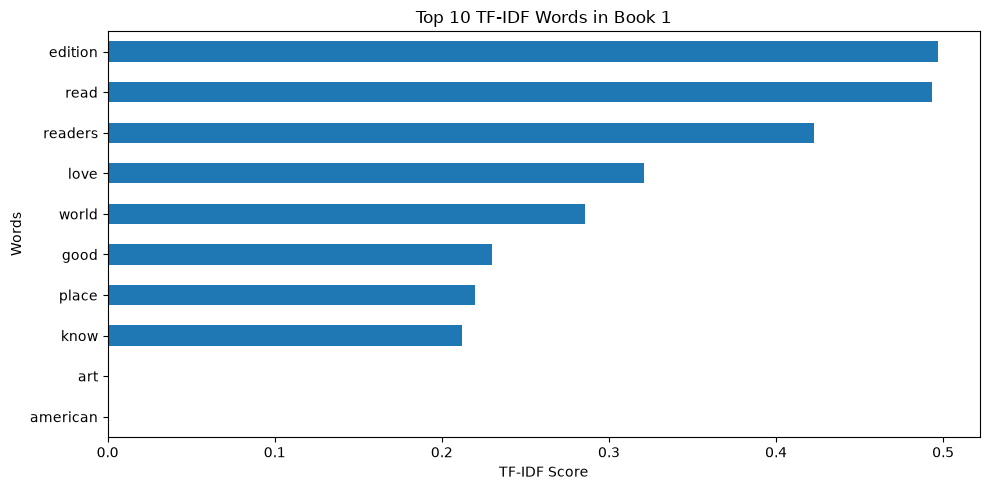

In [22]:
plt.figure(figsize=(10, 5))

top_words.sort_values().plot(kind="barh")

plt.title("Top 10 TF-IDF Words in Book 1")
plt.xlabel("TF-IDF Score")
plt.ylabel("Words")

plt.tight_layout()
plt.show()


In [23]:
tfidf_df.to_csv("../data/tfidf_features.csv", index=False)

print("TF-IDF features saved successfully!")

TF-IDF features saved successfully!
